# Employee Sentiment Analysis

## Project Overview

This project analyzes employee messages using Natural Language Processing (NLP).

The main objectives are:
- Classify messages as Positive, Negative, or Neutral.
- Explore patterns in the dataset.
- Calculate monthly employee sentiment scores.
- Rank employees by monthly sentiment scores.
- Identify employees meeting the rolling 30-day negative-message threshold.
- Evaluate sentiment trends using Linear Regression.

In [58]:
from pathlib import Path

# Check the notebook's current working directory
print("Current directory:", Path.cwd())

# List CSV files without displaying their contents
csv_files = list(Path.cwd().glob("*.csv"))

print("CSV files found:", [file.name for file in csv_files])

Current directory: c:\Users\gg\Documents\employee-sentiment-analysis
CSV files found: []


In [59]:
from pathlib import Path

file_path = Path("data") / "test.csv"

print("File exists:", file_path.exists())

File exists: True


In [60]:
from pathlib import Path

project = Path.cwd()

print("Project folder:", project)
print("\nDoes the data folder exist?", Path("data").is_dir())

print("\nFiles inside the data folder:")
if Path("data").is_dir():
    for file in Path("data").iterdir():
        print(file.name)

print("\nDataset files found elsewhere in the project:")
for file in project.rglob("*"):
    if (
        file.is_file()
        and ".venv" not in file.parts
        and file.suffix.lower() in [".csv", ".xlsx", ".xls"]
    ):
        print(file.relative_to(project))

Project folder: c:\Users\gg\Documents\employee-sentiment-analysis

Does the data folder exist? True

Files inside the data folder:
test.csv
test.xlsx

Dataset files found elsewhere in the project:
data\test.csv
data\test.xlsx


In [61]:
import pandas as pd
from pathlib import Path

file_path = Path("data") / "test.xlsx"

excel_file = pd.ExcelFile(file_path)

print("Worksheets found:", excel_file.sheet_names)

Worksheets found: ['in']


In [62]:
import pandas as pd
from pathlib import Path

# Define the input and output file paths
excel_path = Path("data") / "test.xlsx"
csv_path = Path("data") / "test.csv"

# Load the worksheet named "in"
df = pd.read_excel(excel_path, sheet_name="in")

# Save the dataset as CSV without the extra DataFrame index
df.to_csv(csv_path, index=False, encoding="utf-8-sig")

# Verify the conversion
print("CSV created:", csv_path.exists())
print("Dataset shape:", df.shape)
print("Column names:", df.columns.tolist())

CSV created: True
Dataset shape: (2191, 4)
Column names: ['Subject', 'body', 'date', 'from']


In [63]:
from pathlib import Path
import pandas as pd

# Locate and load the dataset
csv_path = Path("data") / "test.csv"
df = pd.read_csv(csv_path)

# Inspect the dataset structure
print("Dataset shape:", df.shape)
print("\nColumns:", df.columns.tolist())
print("\nData types:\n", df.dtypes)
print("\nMissing values:\n", df.isnull().sum())
print("\nDuplicate rows:", df.duplicated().sum())

Dataset shape: (2191, 4)

Columns: ['Subject', 'body', 'date', 'from']

Data types:
 Subject    str
body       str
date       str
from       str
dtype: object

Missing values:
 Subject    0
body       0
date       0
from       0
dtype: int64

Duplicate rows: 0


In [64]:
# Convert date text into datetime values.
# UTC provides a consistent timeline when timestamps have time zones.
df["date_parsed"] = pd.to_datetime(
    df["date"],
    format="mixed",
    errors="coerce",
    utc=True
)

# Check the conversion results
valid_dates = df["date_parsed"].notna().sum()
invalid_dates = df["date_parsed"].isna().sum()

print("Total records:", len(df))
print("Valid dates:", valid_dates)
print("Invalid dates:", invalid_dates)

if valid_dates > 0:
    print("Earliest date:", df["date_parsed"].min())
    print("Latest date:", df["date_parsed"].max())

Total records: 2191
Valid dates: 2191
Invalid dates: 0
Earliest date: 2010-01-01 00:00:00+00:00
Latest date: 2011-12-31 00:00:00+00:00


In [65]:
# Normalize sender strings for inspection
sender = (
    df["from"]
    .astype("string")
    .str.strip()
    .str.lower()
)

# Represent blank strings as missing values
sender = sender.mask(sender.eq(""), pd.NA)

# Inspect sender data quality without displaying identities
print("Total messages:", len(sender))
print("Unique sender values:", sender.nunique())
print("Missing sender values:", sender.isna().sum())
print(
    "Values containing @:",
    sender.str.contains("@", na=False).sum()
)

Total messages: 2191
Unique sender values: 10
Missing sender values: 0
Values containing @: 2191


In [66]:
# Inspect sender formats without printing private identities

sender_raw = df["from"].astype("string").str.strip()

has_at = sender_raw.str.contains("@", na=False)
has_angle_brackets = sender_raw.str.contains(r"[<>]", na=False)
is_blank = sender_raw.isna() | sender_raw.eq("")

print("Total records:", len(sender_raw))
print("Blank or missing sender values:", is_blank.sum())
print("Values containing @:", has_at.sum())
print("Values containing angle brackets:", has_angle_brackets.sum())
print("Distinct sender values:", sender_raw.nunique())

Total records: 2191
Blank or missing sender values: 0
Values containing @: 2191
Values containing angle brackets: 0
Distinct sender values: 10


In [67]:
from textblob import TextBlob

# Combine each email's subject and body
df["message_text"] = (
    df["Subject"].fillna("").astype(str).str.strip()
    + "\n"
    + df["body"].fillna("").astype(str).str.strip()
).str.strip()

# Calculate sentiment polarity for each email
df["polarity"] = df["message_text"].apply(
    lambda text: TextBlob(text).sentiment.polarity
)

print("Messages processed:", len(df))
print("\nPolarity summary:")
print(df["polarity"].describe())

Messages processed: 2191

Polarity summary:
count    2191.000000
mean        0.117324
std         0.222571
min        -1.000000
25%         0.000000
50%         0.083333
75%         0.207359
max         1.000000
Name: polarity, dtype: float64


In [68]:
# Assign an initial sentiment label using documented thresholds

def classify_sentiment(polarity):
    if polarity < -0.1:
        return "Negative"
    elif polarity > 0.1:
        return "Positive"
    else:
        return "Neutral"


df["Sentiment"] = df["polarity"].apply(classify_sentiment)

# Summarize the assigned labels
print("Sentiment labeling completed.")
print("\nLabel counts:")
print(df["Sentiment"].value_counts())

print("\nLabel percentages:")
print(
    (df["Sentiment"].value_counts(normalize=True) * 100).round(2)
)

Sentiment labeling completed.

Label counts:
Sentiment
Neutral     1019
Positive     976
Negative     196
Name: count, dtype: int64

Label percentages:
Sentiment
Neutral     46.51
Positive    44.55
Negative     8.95
Name: proportion, dtype: float64


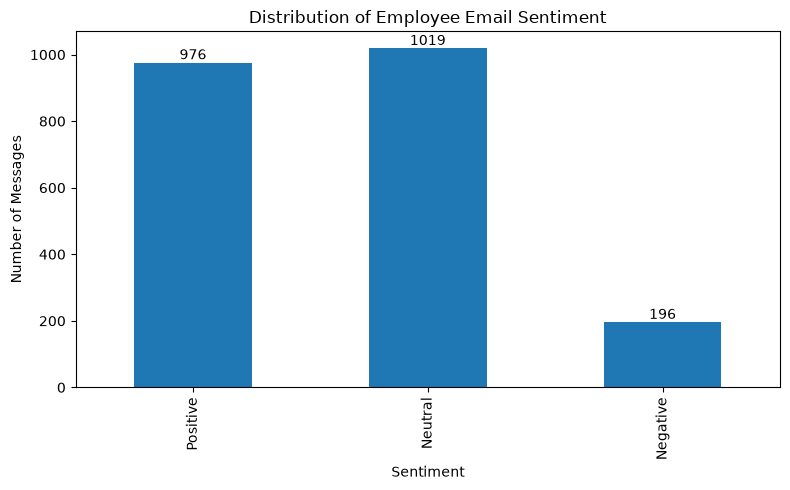

In [69]:
import matplotlib.pyplot as plt
from pathlib import Path

# Create a folder for project visualizations
output_dir = Path("visualizations")
output_dir.mkdir(parents=True, exist_ok=True)

# Count messages in each sentiment category
sentiment_counts = (
    df["Sentiment"]
    .value_counts()
    .reindex(["Positive", "Neutral", "Negative"], fill_value=0)
)

# Plot the sentiment distribution
ax = sentiment_counts.plot(kind="bar", figsize=(8, 5))

ax.set_title("Distribution of Employee Email Sentiment")
ax.set_xlabel("Sentiment")
ax.set_ylabel("Number of Messages")
ax.bar_label(ax.containers[0], fmt="%d")

plt.tight_layout()

# Save the chart for the project deliverables
plt.savefig(
    output_dir / "sentiment_distribution.png",
    dpi=150,
    bbox_inches="tight"
)

plt.show()

### Observation

Neutral labels account for 46.51% of the messages, followed by
Positive labels at 44.55% and Negative labels at 8.95%.
These percentages describe TextBlob's classifications under the
selected thresholds. They should not be interpreted as verified
measurements of employee satisfaction or as evidence of flight risk.

In [70]:
# Create a year-month label from each parsed email date
df["Month"] = df["date_parsed"].dt.strftime("%Y-%m")

# Count sentiment labels in each month
monthly_sentiment_counts = (
    df.groupby(["Month", "Sentiment"])
      .size()
      .unstack(fill_value=0)
      .reindex(
          columns=["Positive", "Neutral", "Negative"],
          fill_value=0
      )
      .sort_index()
)

print(monthly_sentiment_counts)

Sentiment  Positive  Neutral  Negative
Month                                 
2010-01          38       45         8
2010-02          43       39         9
2010-03          36       48         7
2010-04          36       48         8
2010-05          43       42         6
2010-06          39       42        11
2010-07          37       46         8
2010-08          43       38        10
2010-09          35       51         5
2010-10          35       52         4
2010-11          36       40        15
2010-12          34       47        10
2011-01          41       44         6
2011-02          39       42        10
2011-03          44       36        12
2011-04          48       36         8
2011-05          41       44         7
2011-06          50       35         6
2011-07          43       40         8
2011-08          40       47         4
2011-09          51       35         5
2011-10          42       38        11
2011-11          44       40         8
2011-12          38      

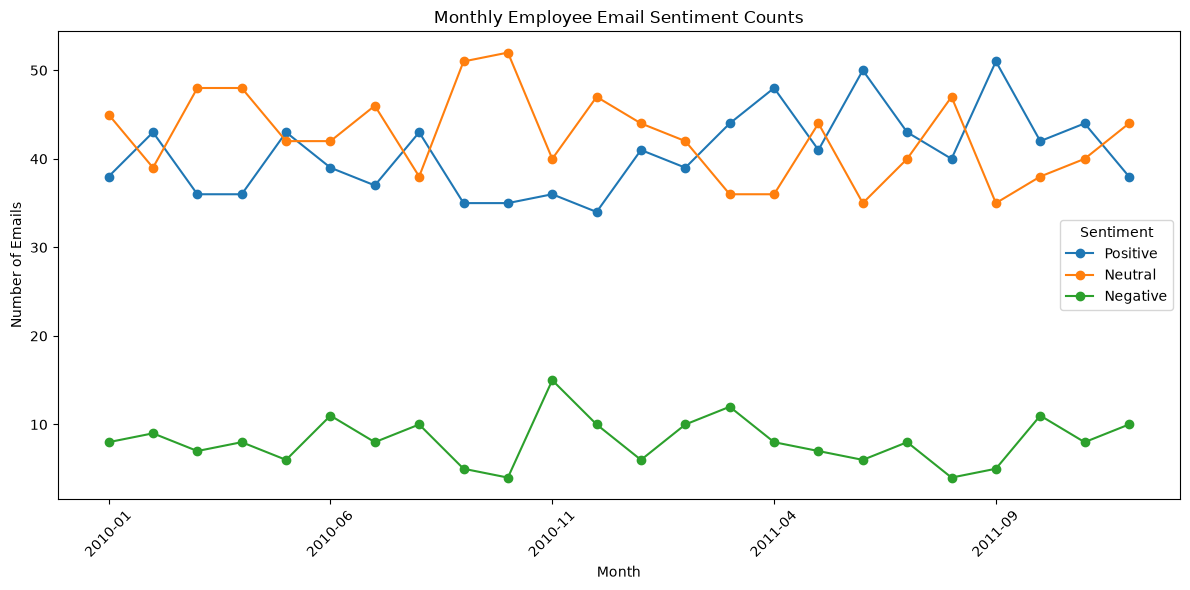

In [71]:
import matplotlib.pyplot as plt

ax = monthly_sentiment_counts.plot(
    kind="line",
    marker="o",
    figsize=(12, 6)
)

ax.set_title("Monthly Employee Email Sentiment Counts")
ax.set_xlabel("Month")
ax.set_ylabel("Number of Emails")
ax.legend(title="Sentiment")

plt.xticks(rotation=45)
plt.tight_layout()

plt.savefig(
    "visualizations/monthly_sentiment_trend.png",
    dpi=150,
    bbox_inches="tight"
)

plt.show()

In [72]:
# Top 3 employees with positive monthly scores
top_positive = (
    monthly_employee_scores[
        monthly_employee_scores["monthly_sentiment_score"] > 0
    ]
    .sort_values(
        ["Month", "monthly_sentiment_score", "sender_id"],
        ascending=[True, False, True]
    )
    .groupby("Month", group_keys=False)
    .head(3)
    .copy()
)

top_positive["Rank"] = (
    top_positive.groupby("Month").cumcount() + 1
)


# Top 3 employees with negative monthly scores
top_negative = (
    monthly_employee_scores[
        monthly_employee_scores["monthly_sentiment_score"] < 0
    ]
    .sort_values(
        ["Month", "monthly_sentiment_score", "sender_id"],
        ascending=[True, True, True]
    )
    .groupby("Month", group_keys=False)
    .head(3)
    .copy()
)

top_negative["Rank"] = (
    top_negative.groupby("Month").cumcount() + 1
)


# Check the ranking results without printing employee identities
print("Positive ranking rows:", len(top_positive))
print("Negative ranking rows:", len(top_negative))

print(
    "Months with positive rankings:",
    top_positive["Month"].nunique()
)
print(
    "Months with negative rankings:",
    top_negative["Month"].nunique()
)

Positive ranking rows: 72
Negative ranking rows: 2
Months with positive rankings: 24
Months with negative rankings: 2


In [73]:
print("df exists:", "df" in globals())
print(
    "monthly_employee_scores exists:",
    "monthly_employee_scores" in globals()
)

if "df" in globals():
    print("\nCurrent DataFrame columns:")
    print(df.columns.tolist())

    for column in [
        "Sentiment",
        "Month",
        "message_score",
        "sender_id"
    ]:
        print(f"{column} exists:", column in df.columns)
        

df exists: True
monthly_employee_scores exists: True

Current DataFrame columns:
['Subject', 'body', 'date', 'from', 'date_parsed', 'message_text', 'polarity', 'Sentiment', 'Month']
Sentiment exists: True
Month exists: True
message_score exists: False
sender_id exists: False


In [74]:
# 1. Normalize sender identifiers
df["sender_id"] = (
    df["from"].astype("string").str.strip().str.lower()
)

# 2. Convert sentiment labels into numerical scores
score_map = {
    "Positive": 1,
    "Neutral": 0,
    "Negative": -1
}

df["message_score"] = df["Sentiment"].map(score_map)

# 3. Validate the score mapping
if df["message_score"].isna().any():
    raise ValueError(
        "Some sentiment labels could not be converted to scores."
    )

# 4. Calculate each employee's score for each month
monthly_employee_scores = (
    df.groupby(["sender_id", "Month"])
    .agg(
        monthly_sentiment_score=("message_score", "sum"),
        total_messages=("message_score", "size"),
        positive_messages=(
            "Sentiment", lambda s: s.eq("Positive").sum()
        ),
        neutral_messages=(
            "Sentiment", lambda s: s.eq("Neutral").sum()
        ),
        negative_messages=(
            "Sentiment", lambda s: s.eq("Negative").sum()
        )
    )
    .reset_index()
)

# 5. Validate the result
print("Missing message scores:", df["message_score"].isna().sum())
print("Employee-month records:", len(monthly_employee_scores))
print(
    "Distinct employees:",
    monthly_employee_scores["sender_id"].nunique()
)
print(
    "Months covered:",
    monthly_employee_scores["Month"].nunique()
)

Missing message scores: 0
Employee-month records: 240
Distinct employees: 10
Months covered: 24


In [75]:
# Top 3 positive monthly scores
top_positive = (
    monthly_employee_scores[
        monthly_employee_scores["monthly_sentiment_score"] > 0
    ]
    .sort_values(
        ["Month", "monthly_sentiment_score", "sender_id"],
        ascending=[True, False, True]
    )
    .groupby("Month", group_keys=False)
    .head(3)
    .copy()
)

top_positive["Rank"] = (
    top_positive.groupby("Month").cumcount() + 1
)


# Top 3 negative monthly scores
top_negative = (
    monthly_employee_scores[
        monthly_employee_scores["monthly_sentiment_score"] < 0
    ]
    .sort_values(
        ["Month", "monthly_sentiment_score", "sender_id"],
        ascending=[True, True, True]
    )
    .groupby("Month", group_keys=False)
    .head(3)
    .copy()
)

top_negative["Rank"] = (
    top_negative.groupby("Month").cumcount() + 1
)


# Validate the ranking results without exposing email addresses
print("Positive ranking rows:", len(top_positive))
print("Negative ranking rows:", len(top_negative))

print("Months with positive rankings:", top_positive["Month"].nunique())
print("Months with negative rankings:", top_negative["Month"].nunique())

Positive ranking rows: 72
Negative ranking rows: 2
Months with positive rankings: 24
Months with negative rankings: 2


In [76]:
# 1. Keep only negative emails
negative_emails = df.loc[
    df["Sentiment"].eq("Negative"),
    ["sender_id", "date_parsed"]
].copy()

# Sort emails by employee and timestamp
negative_emails = negative_emails.sort_values(
    ["sender_id", "date_parsed"]
)

# 2. Count negative emails within each rolling 30-day window
negative_emails["negative_count_30d"] = float("nan")

for sender_id, group in negative_emails.groupby("sender_id", sort=False):
    rolling_counts = (
        group.set_index("date_parsed")
        .assign(negative_email=1)["negative_email"]
        .rolling("30D", closed="both")
        .sum()
    )

    negative_emails.loc[
        group.index, "negative_count_30d"
    ] = rolling_counts.to_numpy()

negative_emails["negative_count_30d"] = (
    negative_emails["negative_count_30d"].astype(int)
)

# 3. Flag events where the rolling count reaches 4 or more
flagged_events = negative_emails.loc[
    negative_emails["negative_count_30d"] >= 4
].copy()

# 4. Summarize flagged employees
flight_risk_summary = (
    flagged_events.groupby("sender_id")
    .agg(
        first_flag_date=("date_parsed", "min"),
        max_negative_emails_30d=("negative_count_30d", "max")
    )
    .reset_index()
)

# 5. Validate results without exposing employee identities
print("Negative emails analyzed:", len(negative_emails))
print("Flagging events:", len(flagged_events))
print("Employees flagged:", flight_risk_summary["sender_id"].nunique())

print(
    "Maximum negative emails in any 30-day window:",
    negative_emails["negative_count_30d"].max()
    if not negative_emails.empty else 0
)

print("\nFlagging summary (dates and counts only):")
print(flight_risk_summary.drop(columns=["sender_id"]).to_string(index=False))

Negative emails analyzed: 196
Flagging events: 13
Employees flagged: 6
Maximum negative emails in any 30-day window: 6

Flagging summary (dates and counts only):
          first_flag_date  max_negative_emails_30d
2010-11-17 00:00:00+00:00                        6
2011-02-26 00:00:00+00:00                        4
2011-12-20 00:00:00+00:00                        6
2011-04-12 00:00:00+00:00                        4
2011-01-01 00:00:00+00:00                        4
2010-07-07 00:00:00+00:00                        4


In [77]:
# Create a separate dataset for machine learning
model_df = monthly_employee_scores.copy()

# Convert the month label into a real datetime value
model_df["Month"] = pd.to_datetime(
    model_df["Month"] + "-01"
)

# Sort each employee's records chronologically
model_df = model_df.sort_values(
    ["sender_id", "Month"]
).copy()

# Features: sentiment counts from the previous month
feature_columns = [
    "positive_messages",
    "neutral_messages",
    "negative_messages"
]

for column in feature_columns:
    model_df[f"previous_{column}"] = (
        model_df.groupby("sender_id")[column].shift(1)
    )

# Keep records that have a previous month
model_df = model_df.dropna(
    subset=[f"previous_{column}" for column in feature_columns]
).copy()

# Inspect the prepared dataset without exposing employee identities
print("Model dataset shape:", model_df.shape)
print("Months covered:", model_df["Month"].nunique())
print("Missing previous-month features:")
print(
    model_df[
        [f"previous_{column}" for column in feature_columns]
    ].isna().sum()
)

print("\nPrepared features and target:")
print(
    model_df[
        [
            "Month",
            "previous_positive_messages",
            "previous_neutral_messages",
            "previous_negative_messages",
            "monthly_sentiment_score"
        ]
    ].head(10).to_string(index=False)
)

Model dataset shape: (230, 10)
Months covered: 23
Missing previous-month features:
previous_positive_messages    0
previous_neutral_messages     0
previous_negative_messages    0
dtype: int64

Prepared features and target:
     Month  previous_positive_messages  previous_neutral_messages  previous_negative_messages  monthly_sentiment_score
2010-02-01                         1.0                        1.0                         0.0                        7
2010-03-01                         8.0                        5.0                         1.0                        3
2010-04-01                         3.0                        8.0                         0.0                        2
2010-05-01                         2.0                        4.0                         0.0                        1
2010-06-01                         1.0                        3.0                         0.0                        0
2010-07-01                         1.0                        3

In [78]:
# Training data: February 2010 through June 2011
train_df = model_df[
    model_df["Month"] < pd.Timestamp("2011-07-01")
].copy()

# Test data: July through December 2011
test_df = model_df[
    model_df["Month"] >= pd.Timestamp("2011-07-01")
].copy()

print("Training rows:", len(train_df))
print("Testing rows:", len(test_df))

print(
    "Training period:",
    train_df["Month"].min(),
    "to",
    train_df["Month"].max()
)

print(
    "Testing period:",
    test_df["Month"].min(),
    "to",
    test_df["Month"].max()
)

Training rows: 170
Testing rows: 60
Training period: 2010-02-01 00:00:00 to 2011-06-01 00:00:00
Testing period: 2011-07-01 00:00:00 to 2011-12-01 00:00:00


In [79]:
from sklearn.linear_model import LinearRegression

# 1. Choose the input features
model_features = [
    "previous_positive_messages",
    "previous_neutral_messages",
    "previous_negative_messages"
]

# 2. Separate inputs (X) and target (y)
X_train = train_df[model_features]
y_train = train_df["monthly_sentiment_score"]

X_test = test_df[model_features]
y_test = test_df["monthly_sentiment_score"]

# 3. Create the model
model = LinearRegression()

# 4. Train the model
model.fit(X_train, y_train)

# 5. Predict scores for the unseen test data
y_pred = model.predict(X_test)

print("Training completed.")
print("Training records:", len(X_train))
print("Testing records:", len(X_test))
print("Number of predictions:", len(y_pred))
print("\nFirst 10 predictions:")
print(y_pred[:10])

Training completed.
Training records: 170
Testing records: 60
Number of predictions: 60

First 10 predictions:
[2.66788071 4.61987857 2.92686405 2.66788071 3.013941   3.01103766
 3.4519836  2.91124666 3.14946177 2.54732148]


In [80]:
import numpy as np
import pandas as pd
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

# Evaluate the trained model on unseen test data
mae = mean_absolute_error(y_test, y_pred)

rmse = np.sqrt(
    mean_squared_error(y_test, y_pred)
)

r2 = r2_score(y_test, y_pred)

print("Linear Regression Evaluation")
print("MAE:", round(mae, 3))
print("RMSE:", round(rmse, 3))
print("R²:", round(r2, 3))

# Establish a simple baseline using the training-set mean
baseline_pred = np.full(
    shape=len(y_test),
    fill_value=y_train.mean()
)

baseline_mae = mean_absolute_error(
    y_test, baseline_pred
)

baseline_rmse = np.sqrt(
    mean_squared_error(y_test, baseline_pred)
)

print("\nBaseline Evaluation (training mean)")
print("Baseline MAE:", round(baseline_mae, 3))
print("Baseline RMSE:", round(baseline_rmse, 3))

# Compare predictions with actual scores
prediction_check = pd.DataFrame({
    "Month": test_df["Month"].dt.strftime("%Y-%m").to_numpy(),
    "Actual score": y_test.to_numpy(),
    "Predicted score": y_pred,
    "Absolute error": np.abs(
        y_test.to_numpy() - y_pred
    )
})

print("\nFirst 10 predictions compared with actual scores:")
print(prediction_check.head(10).round(2).to_string(index=False))

Linear Regression Evaluation
MAE: 2.411
RMSE: 2.858
R²: -0.063

Baseline Evaluation (training mean)
Baseline MAE: 2.3
Baseline RMSE: 2.796

First 10 predictions compared with actual scores:
  Month  Actual score  Predicted score  Absolute error
2011-07             1             2.67            1.67
2011-08             2             4.62            2.62
2011-09             5             2.93            2.07
2011-10             0             2.67            2.67
2011-11             6             3.01            2.99
2011-12             0             3.01            3.01
2011-07             0             3.45            3.45
2011-08             4             2.91            1.09
2011-09             6             3.15            2.85
2011-10             4             2.55            1.45


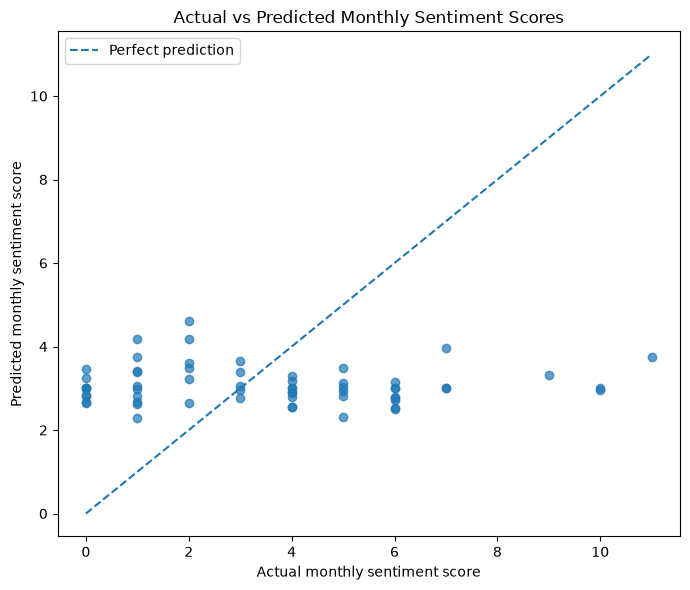

Chart saved: True


In [81]:
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np

output_dir = Path("visualizations")
output_dir.mkdir(parents=True, exist_ok=True)

actual = np.asarray(y_test)
predicted = np.asarray(y_pred)

low = float(min(actual.min(), predicted.min()))
high = float(max(actual.max(), predicted.max()))

plt.figure(figsize=(7, 6))

plt.scatter(actual, predicted, alpha=0.7)
plt.plot(
    [low, high],
    [low, high],
    linestyle="--",
    label="Perfect prediction"
)

plt.title("Actual vs Predicted Monthly Sentiment Scores")
plt.xlabel("Actual monthly sentiment score")
plt.ylabel("Predicted monthly sentiment score")
plt.legend()
plt.tight_layout()

chart_path = output_dir / "regression_actual_vs_predicted.png"
plt.savefig(chart_path, dpi=150, bbox_inches="tight")
plt.show()

print("Chart saved:", chart_path.exists())

In [82]:
# Select the 3 lowest-scoring employees in each month
top_negative = (
    monthly_employee_scores
    .sort_values(
        ["Month", "monthly_sentiment_score", "sender_id"],
        ascending=[True, True, True]
    )
    .groupby("Month", group_keys=False)
    .head(3)
    .copy()
)

# Assign ranks starting from 1 for each month
top_negative["Rank"] = (
    top_negative.groupby("Month").cumcount() + 1
)

# Validate ranking results without exposing employee identities
print("Lowest-score ranking rows:", len(top_negative))
print("Months covered:", top_negative["Month"].nunique())

print("\nRows per month:")
print(top_negative.groupby("Month").size().value_counts().sort_index())

Lowest-score ranking rows: 72
Months covered: 24

Rows per month:
3    24
Name: count, dtype: int64


In [83]:
print(
    top_negative[
        [
            "Month",
            "Rank",
            "monthly_sentiment_score",
            "total_messages",
            "negative_messages"
        ]
    ].head(12).to_string(index=False)
)

  Month  Rank  monthly_sentiment_score  total_messages  negative_messages
2010-01     1                        0               3                  0
2010-01     2                        1               2                  0
2010-01     3                        2               7                  1
2010-02     1                        0               6                  2
2010-02     2                        1               8                  1
2010-02     3                        1               1                  0
2010-03     1                        0               1                  0
2010-03     2                        1              11                  2
2010-03     3                        1               4                  0
2010-04     1                        1               2                  0
2010-04     2                        2               6                  0
2010-04     3                        2              12                  2


In [84]:
# Independently verify the lowest three scores per month
expected_lowest = (
    monthly_employee_scores
    .sort_values(
        ["Month", "monthly_sentiment_score", "sender_id"],
        ascending=[True, True, True]
    )
    .groupby("Month", group_keys=False)
    .head(3)
)

# Check the number of records
assert len(top_positive) == 72
assert len(top_negative) == 72

# Check that every month has exactly three ranked records
assert top_positive.groupby("Month").size().eq(3).all()
assert top_negative.groupby("Month").size().eq(3).all()

# Check positive rankings really have positive scores
assert top_positive["monthly_sentiment_score"].gt(0).all()

# Check the lowest-score ranking matches our independent calculation
pd.testing.assert_frame_equal(
    top_negative[
        ["sender_id", "Month", "monthly_sentiment_score"]
    ].reset_index(drop=True),
    expected_lowest[
        ["sender_id", "Month", "monthly_sentiment_score"]
    ].reset_index(drop=True)
)

print("All ranking validation checks passed.")

All ranking validation checks passed.


In [85]:
from pathlib import Path

# Core dataset checks
assert len(df) == 2191, "Unexpected dataset row count"
assert df["Sentiment"].notna().all(), "Missing sentiment labels"
assert df["message_score"].notna().all(), "Missing message scores"

# Monthly analysis checks
assert len(monthly_employee_scores) == 240
assert monthly_employee_scores["sender_id"].nunique() == 10
assert monthly_employee_scores["Month"].nunique() == 24

# Ranking checks
assert len(top_positive) == 72
assert len(top_negative) == 72
assert top_positive.groupby("Month").size().eq(3).all()
assert top_negative.groupby("Month").size().eq(3).all()

# Flight-risk checks
assert len(negative_emails) == 196
assert negative_emails["negative_count_30d"].notna().all()

# Model checks
assert len(train_df) == 170
assert len(test_df) == 60
assert len(y_pred) == 60

print("All core data, ranking, and model checks passed.")

# Check generated visualization files
visualization_dir = Path("visualizations")

expected_images = [
    "sentiment_distribution.png",
    "monthly_sentiment_trend.png",
    "regression_actual_vs_predicted.png",
]

print("\nVisualization file checks:")
for filename in expected_images:
    path = visualization_dir / filename
    print(f"{filename}: {'FOUND' if path.exists() else 'MISSING'}")

All core data, ranking, and model checks passed.

Visualization file checks:
sentiment_distribution.png: FOUND
monthly_sentiment_trend.png: FOUND
regression_actual_vs_predicted.png: FOUND
